# WellbeingIQ · Notebook 3: Modeling, Tuning & Evaluation
**Input:** `WellbeingIQ_cleaned.csv` · **Target:** `Wellness_Category` (At-Risk / Moderate / Good) · **Helper module:** `wellbeing_features.py`

> **Data note:** the dataset is **synthetic**. Scores show how well the pipeline recovers patterns in simulated data, not how it would perform on real students. Not a medical tool.

**Plan**
1. Stratified train/test split (the test set is touched only once, at the end).
2. Leakage-safe pipeline: feature engineering, imputation, encoding and scaling are all fitted on training data only.
3. Compare Logistic Regression, Decision Tree, Random Forest and Gradient Boosting against a dummy baseline with 5-fold cross-validation.
4. Tune each model, run an ablation (with/without `Addiction_Score` and engineered features), tune the At-Risk decision threshold.
5. Final evaluation on the held-out test set, then save the model for SHAP (Notebook 4) and the dashboard.

In [1]:
import pandas as pd, numpy as np, json, joblib, warnings, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, recall_score, f1_score, accuracy_score, precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from wellbeing_features import add_features
import os; os.makedirs('cache', exist_ok=True)
def cached(key, fn):
    # run a slow step once and reuse the saved result later (delete the cache folder to recompute)
    p = f'cache/{key}.joblib'
    if os.path.exists(p): return joblib.load(p)
    r = fn(); joblib.dump(r, p); return r
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); RS = 42
ORDER = ['At-Risk','Moderate','Good']

## 1. Data and train/test split

In [2]:
df = pd.read_csv('WellbeingIQ_cleaned.csv')
DROP = ['Student_ID','Mental_Health_Score','Stress_Level','Wellness_Category']   # Stress_Level excluded: built partly from the score (leakage)
FEATURES = [c for c in df.columns if c not in DROP]
X, y = df[FEATURES], df['Wellness_Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print('train', X_train.shape, '| test', X_test.shape)
print(pd.DataFrame({'train %':y_train.value_counts(normalize=True).round(3),'test %':y_test.value_counts(normalize=True).round(3)}).loc[ORDER])
print('missing cells in train:', int(X_train.isna().sum().sum()), '(imputed inside the pipeline)')

train (4800, 24) | test (1200, 24)
                   train %  test %
Wellness_Category                 
At-Risk              0.189   0.189
Moderate             0.484   0.484
Good                 0.327   0.327
missing cells in train: 689 (imputed inside the pipeline)


## 2. Leakage-safe pipeline

In [3]:
def make_pipe(model, engineer=True):
    num = Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())])
    cat = Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    prep = ColumnTransformer([('num',num,make_column_selector(dtype_include=np.number)),
                              ('cat',cat,make_column_selector(dtype_exclude=np.number))])
    fe = FunctionTransformer(add_features) if engineer else FunctionTransformer()
    return Pipeline([('fe',fe),('prep',prep),('clf',model)])

atrisk_recall = make_scorer(lambda a,b: recall_score(a,b,labels=['At-Risk'],average=None)[0])
SCORING = {'accuracy':'accuracy','macro_f1':'f1_macro','macro_precision':'precision_macro','macro_recall':'recall_macro','atrisk_recall':atrisk_recall}
CV = StratifiedKFold(5, shuffle=True, random_state=RS)
def cv_table(pipes, Xtr=None):
    Xtr = X_train if Xtr is None else Xtr; rows=[]
    for name,p in pipes.items():
        r = cross_validate(p, Xtr, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        rows.append({'Model':name, **{k:r['test_'+k].mean() for k in SCORING}, 'macro_f1_std':r['test_macro_f1'].std()})
    return pd.DataFrame(rows).set_index('Model').round(3)

## 3. Baseline comparison (5-fold CV on the training set)

In [4]:
models = {
 'Dummy (majority class)': DummyClassifier(strategy='most_frequent'),
 'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced'),
 'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=RS),
 'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RS, n_jobs=1),
 'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RS)}
base = cached('base', lambda: cv_table({k:make_pipe(m) for k,m in models.items()})); base

,accuracy,macro_f1,macro_precision,macro_recall,atrisk_recall,macro_f1_std
Model,,,,,,
Dummy (majority class),0.484,0.217,0.161,0.333,0.000,0.000
Logistic Regression,0.612,0.615,0.604,0.651,0.740,0.007
Decision Tree,0.555,0.558,0.550,0.602,0.710,0.017
Random Forest,0.624,0.590,0.648,0.569,0.385,0.011
Gradient Boosting,0.597,0.593,0.594,0.593,0.556,0.016


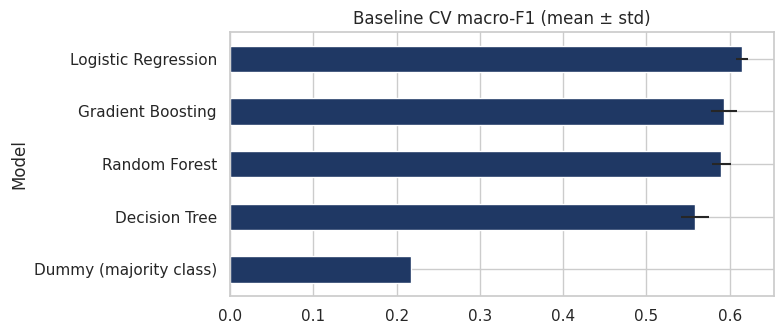

In [5]:
ax = base['macro_f1'].sort_values().plot.barh(xerr=base['macro_f1_std'].reindex(base['macro_f1'].sort_values().index), color='#1F3864', figsize=(8,3.5))
ax.set_title('Baseline CV macro-F1 (mean ± std)'); plt.tight_layout(); plt.show()

## 4. Hyperparameter tuning (GridSearchCV, scored on macro-F1)

In [6]:
grids = {
 'Logistic Regression': (LogisticRegression(max_iter=3000, class_weight='balanced'), {'clf__C':[0.01,0.1,1,10]}),
 'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=RS), {'clf__max_depth':[3,4,5,6,8],'clf__min_samples_leaf':[10,20,50]}),
 'Random Forest': (RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RS, n_jobs=1), {'clf__max_depth':[8,None],'clf__min_samples_leaf':[3,10],'clf__max_features':['sqrt']}),
 'Gradient Boosting': (HistGradientBoostingClassifier(class_weight='balanced', random_state=RS), {'clf__learning_rate':[0.05,0.1],'clf__max_depth':[3,5],'clf__max_iter':[200],'clf__l2_regularization':[0,1.0]})}
tuned, rows = {}, []
for name,(m,g) in grids.items():
    gs = cached('gs_'+name.replace(' ','_'), lambda: GridSearchCV(make_pipe(m), g, cv=CV, scoring='f1_macro', n_jobs=-1).fit(X_train, y_train))
    tuned[name] = gs.best_estimator_
    rows.append({'Model':name,'Baseline macro-F1':base.loc[name,'macro_f1'],'Tuned macro-F1':round(gs.best_score_,3),'Best params':{k.replace('clf__',''):v for k,v in gs.best_params_.items()}})
tune_df = pd.DataFrame(rows).set_index('Model'); pd.set_option('display.max_colwidth',120); tune_df

,Baseline macro-F1,Tuned macro-F1,Best params
Model,,,
Logistic Regression,0.615,0.621,{'C': 0.01}
Decision Tree,0.558,0.561,"{'max_depth': 4, 'min_samples_leaf': 10}"
Random Forest,0.590,0.614,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3}"
Gradient Boosting,0.593,0.598,"{'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 200}"


## 5. Ablation: do `Addiction_Score` and the engineered features help?

In [7]:
best_name = tune_df['Tuned macro-F1'].idxmax(); print('Best tuned model:', best_name)
best_params = tuned[best_name].named_steps['clf'].get_params()
def fresh(): 
    from sklearn.base import clone; return clone(tuned[best_name].named_steps['clf'])
variants = {
 'A: all features + engineered': (make_pipe(fresh()), X_train),
 'B: without Addiction_Score': (make_pipe(fresh()), X_train.drop(columns=['Addiction_Score'])),
 'C: without engineered features': (make_pipe(fresh(), engineer=False), X_train),
 'D: without both': (make_pipe(fresh(), engineer=False), X_train.drop(columns=['Addiction_Score']))}
abl = cached('ablation', lambda: pd.concat({k:cv_table({k:p}, Xtr=x) for k,(p,x) in variants.items()}).droplevel(1))
abl[['accuracy','macro_f1','atrisk_recall','macro_f1_std']]

Best tuned model: Logistic Regression


,accuracy,macro_f1,atrisk_recall,macro_f1_std
A: all features + engineered,0.618,0.621,0.754,0.012
B: without Addiction_Score,0.617,0.621,0.757,0.010
C: without engineered features,0.617,0.620,0.757,0.011
D: without both,0.617,0.620,0.759,0.011


In [8]:
gain_add = abl.loc['A: all features + engineered','macro_f1'] - abl.loc['B: without Addiction_Score','macro_f1']
gain_eng = abl.loc['A: all features + engineered','macro_f1'] - abl.loc['C: without engineered features','macro_f1']
KEEP_ADDICTION = bool(gain_add > 0.01)      # keep the proxy only if it clearly helps
USE_ENGINEERED = bool(gain_eng > 0.0)
print(f'Addiction_Score gain in macro-F1: {gain_add:+.3f} -> keep = {KEEP_ADDICTION}')
print(f'Engineered features gain in macro-F1: {gain_eng:+.3f} -> use = {USE_ENGINEERED}')

Addiction_Score gain in macro-F1: +0.000 -> keep = False
Engineered features gain in macro-F1: +0.001 -> use = True


## 6. Final model and At-Risk decision threshold

In [9]:
FINAL_FEATURES = [c for c in FEATURES if KEEP_ADDICTION or c!='Addiction_Score']
Xtr, Xte = X_train[FINAL_FEATURES], X_test[FINAL_FEATURES]
final = make_pipe(fresh(), engineer=USE_ENGINEERED)
oof = cached('oof', lambda: cross_val_predict(final, Xtr, y_train, cv=CV, method='predict_proba', n_jobs=-1))
classes = np.array(sorted(y_train.unique())); ai = list(classes).index('At-Risk')
def decide(P, t):
    pred = classes[P.argmax(1)].astype(object); pred[P[:,ai]>=t] = 'At-Risk'; return pred
grid = np.arange(0.20,0.61,0.05)
sweep = pd.DataFrame({'threshold':grid,
   'macro_f1':[f1_score(y_train,decide(oof,t),average='macro') for t in grid],
   'atrisk_recall':[recall_score(y_train,decide(oof,t),labels=['At-Risk'],average=None)[0] for t in grid],
   'atrisk_precision':[precision_score(y_train,decide(oof,t),labels=['At-Risk'],average=None)[0] for t in grid]}).round(3)
T = float(sweep.loc[sweep.macro_f1.idxmax(),'threshold']); display(sweep); print('chosen At-Risk threshold (max macro-F1 on cross-validated training predictions):', T)

,threshold,macro_f1,atrisk_recall,atrisk_precision
0,0.20,0.490,0.922,0.361
1,0.25,0.531,0.909,0.395
2,0.30,0.559,0.875,0.426
3,0.35,0.584,0.834,0.458
4,0.40,0.603,0.791,0.491
5,0.45,0.619,0.758,0.524
6,0.50,0.621,0.757,0.528
7,0.55,0.621,0.757,0.528
8,0.60,0.621,0.757,0.528


chosen At-Risk threshold (max macro-F1 on cross-validated training predictions): 0.5


## 7. Held-out test evaluation (used once)

In [10]:
final.fit(Xtr, y_train); P = final.predict_proba(Xte)
pred_default = final.predict(Xte); pred_T = decide(P, T)
def summarize(p): return {'accuracy':accuracy_score(y_test,p),'macro_precision':precision_score(y_test,p,average='macro'),'macro_recall':recall_score(y_test,p,average='macro'),'macro_f1':f1_score(y_test,p,average='macro'),'atrisk_recall':recall_score(y_test,p,labels=['At-Risk'],average=None)[0]}
dummy = make_pipe(DummyClassifier(strategy='most_frequent')).fit(Xtr,y_train).predict(Xte)
lr = make_pipe(LogisticRegression(max_iter=3000,class_weight='balanced')).fit(Xtr,y_train).predict(Xte)
res = pd.DataFrame({'Dummy baseline':summarize(dummy),'Baseline Logistic Regression':summarize(lr),f'Tuned {best_name} (default decision)':summarize(pred_default),f'Tuned {best_name} + At-Risk threshold {T}':summarize(pred_T)}).T.round(3)
res

,accuracy,macro_precision,macro_recall,macro_f1,atrisk_recall
Dummy baseline,0.484,0.161,0.333,0.217,0.000
Baseline Logistic Regression,0.622,0.615,0.662,0.627,0.762
Tuned Logistic Regression (default decision),0.630,0.623,0.670,0.635,0.767
Tuned Logistic Regression + At-Risk threshold 0.5,0.630,0.623,0.670,0.635,0.767


              precision    recall  f1-score   support

     At-Risk      0.547     0.767     0.639       227
    Moderate      0.678     0.499     0.575       581
        Good      0.643     0.745     0.690       392

    accuracy                          0.630      1200
   macro avg      0.623     0.670     0.635      1200
weighted avg      0.642     0.630     0.625      1200



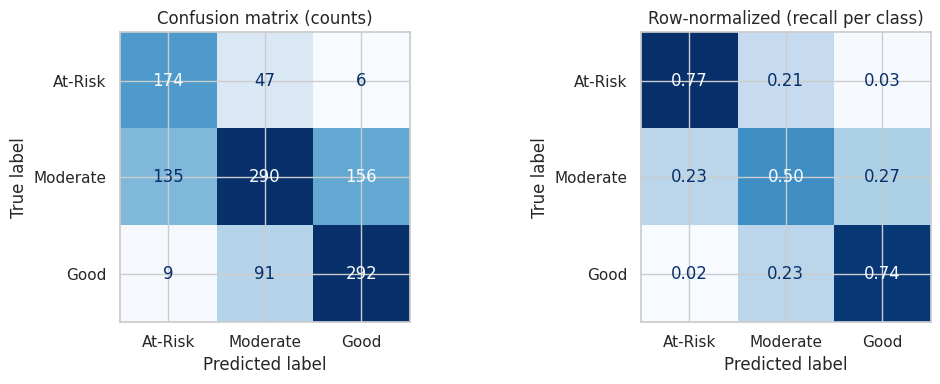

Macro ROC-AUC (one-vs-rest): 0.818


In [11]:
print(classification_report(y_test, pred_T, labels=ORDER, digits=3))
cm = confusion_matrix(y_test, pred_T, labels=ORDER)
fig,ax = plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay(cm,display_labels=ORDER).plot(ax=ax[0],cmap='Blues',colorbar=False); ax[0].set_title('Confusion matrix (counts)')
ConfusionMatrixDisplay(cm/cm.sum(1,keepdims=True),display_labels=ORDER).plot(ax=ax[1],cmap='Blues',colorbar=False,values_format='.2f'); ax[1].set_title('Row-normalized (recall per class)')
plt.tight_layout(); plt.show()
auc = roc_auc_score(pd.get_dummies(y_test)[list(classes)], P, average='macro', multi_class='ovr') if False else roc_auc_score(y_test, P, multi_class='ovr', average='macro', labels=list(final.classes_))
print('Macro ROC-AUC (one-vs-rest):', round(auc,3))

In [12]:
rng = np.random.default_rng(RS); yt = y_test.values; boots=[]
for _ in range(1000):
    i = rng.integers(0,len(yt),len(yt)); boots.append(f1_score(yt[i], pred_T[i], average='macro'))
lo,hi = np.percentile(boots,[2.5,97.5]); print(f'Test macro-F1 {f1_score(yt,pred_T,average="macro"):.3f}  (95% bootstrap CI {lo:.3f} to {hi:.3f})')

Test macro-F1 0.635  (95% bootstrap CI 0.607 to 0.659)


## 8. Save the model for SHAP and the dashboard

In [13]:
joblib.dump(final,'wellbeingiq_model.joblib')
meta = {'model':best_name,'features':FINAL_FEATURES,'engineered_features':bool(USE_ENGINEERED),'classes_order':ORDER,'atrisk_threshold':T,
        'test_metrics':res.iloc[-1].to_dict(),'data':'synthetic','random_state':RS}
json.dump(meta,open('model_card.json','w'),indent=2,default=float)
X_train.to_csv('X_train.csv',index=False); X_test.to_csv('X_test.csv',index=False); y_train.to_csv('y_train.csv',index=False); y_test.to_csv('y_test.csv',index=False)
print(json.dumps({k:meta[k] for k in ['model','engineered_features','atrisk_threshold']}))

{"model": "Logistic Regression", "engineered_features": true, "atrisk_threshold": 0.5}


## 9. Findings and honest reading of the results

| Check | Result |
|---|---|
| Dummy baseline (always predict the biggest class) | macro-F1 0.217 |
| Baseline CV macro-F1 | Logistic Regression 0.615, Random Forest 0.590, Gradient Boosting 0.593, Decision Tree 0.558 |
| After tuning (CV macro-F1) | Logistic Regression 0.621 (C = 0.01), Random Forest 0.614, Gradient Boosting 0.598, Decision Tree 0.561 |
| Ablation | `Addiction_Score` adds +0.000 macro-F1, so it is **dropped**. Engineered features add +0.001, so they are kept but matter little. |
| At-Risk threshold sweep | best value was 0.5, the same as the default, so no gain from threshold tuning |
| **Held-out test set** | accuracy 0.630, **macro-F1 0.635** (95% CI 0.607 to 0.659), **At-Risk recall 0.767**, macro ROC-AUC 0.818 |

**Selected model:** Logistic Regression (regularized, balanced class weights) with engineered features, without `Addiction_Score`. Saved as `wellbeingiq_model.joblib`.

**How to read this**
- The model is far above the dummy baseline (0.635 vs 0.217 macro-F1), so it has clearly learned the habit patterns.
- **The simplest model won.** In this simulated dataset the score is mostly an additive mix of habits plus random noise. Trees and boosting have no strong non-linear pattern to exploit, so they do not beat Logistic Regression. On real data this could differ, so we do not claim this ranking would hold there.
- **About 63% accuracy is a realistic ceiling here.** The noise built into the score limits how well any model can separate neighbouring classes. A result far above this would be suspicious.
- **At-Risk recall (0.77) is strong, precision (0.55) is modest.** The model catches about three in four At-Risk students but also raises false alarms. For a screening and awareness tool this is the safer trade-off, and the dashboard wording should reflect uncertainty.
- **Moderate is the hardest class** (recall 0.50), because it sits between two cut-offs and scores near a boundary look alike.
- Feature engineering and extra complexity brought almost nothing, which is itself a useful finding to report.

**Limits:** synthetic data; one random split plus cross-validation; cut-offs of 5.5 and 7.5 are a modeling choice.

**Next:** Notebook 4 uses SHAP on the saved model to explain which habits push a student toward risk, then the GenAI coach and the dashboard are built on top.
